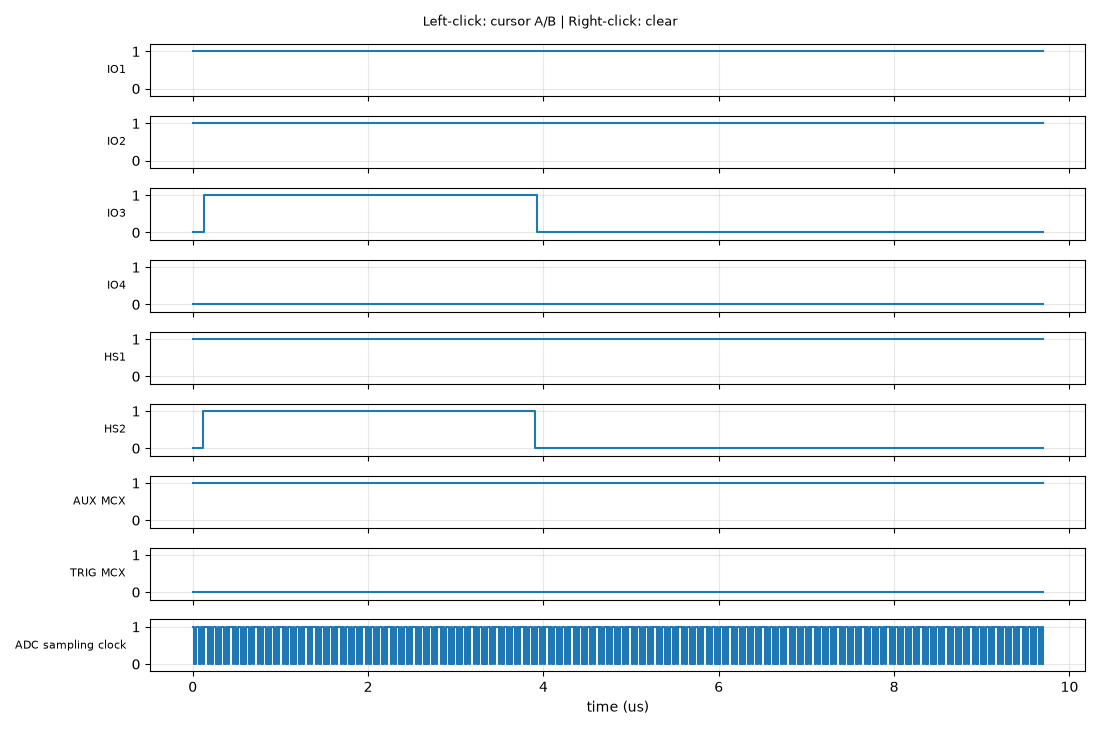

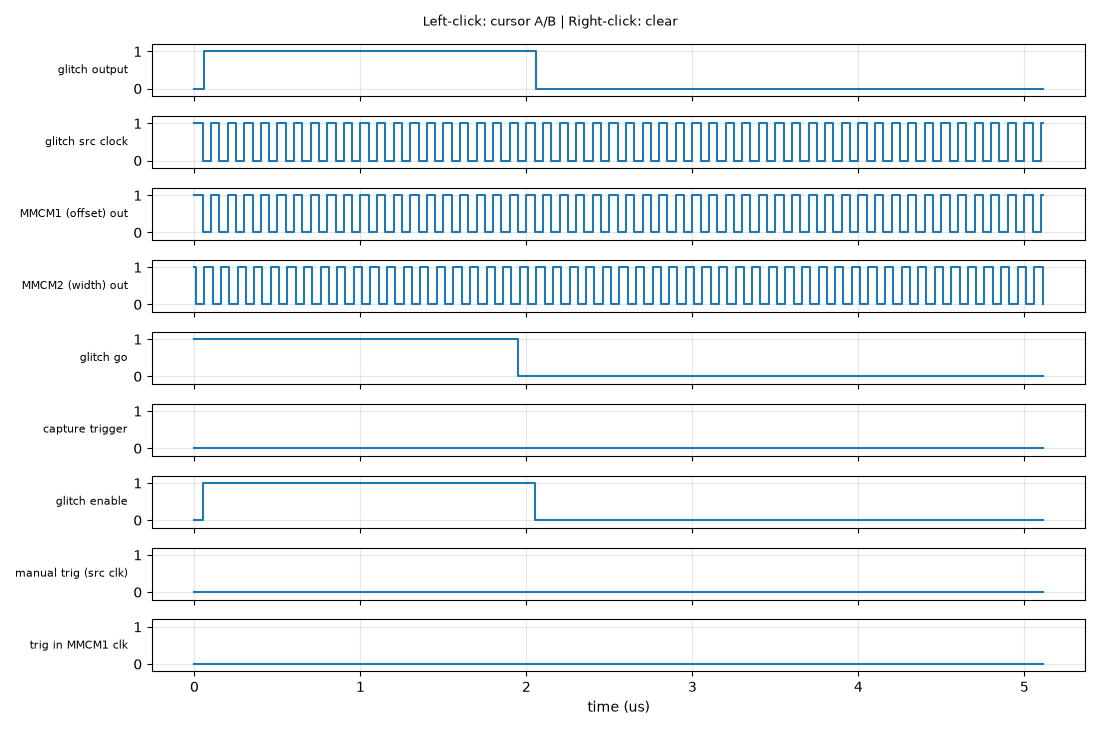

In [1]:
%run ./LibLogicAnalyserGlitchTools.ipynb

import chipwhisperer as cw

try:
    scope.dis()
except:
    pass
try:
    fig1.dis()
except:
    pass
try:
    fig2.dis()
except:
    pass

scope = cw.scope()
scope.default_setup(verbose=False)

scope.clock.clkgen_src = 'system'
scope.clock.clkgen_freq = 10e6
scope.glitch.enabled = True
scope.glitch.clk_src = 'pll'
scope.clock.fpga_vco_freq = 600e6
scope.glitch.output = 'enable_only'
scope.glitch.trigger_src = 'manual'
scope.glitch.repeat = 20            # long enough for the LA to sample
assert scope.glitch.mmcm_locked

scope.io.glitch_hp = False          # no crowbar needed for this test
scope.io.glitch_lp = False
scope.io.tio4 = 'high_z'
scope.io.hs2 = 'glitch'

scope.LA.enabled = True
scope.LA.capture_group = 'CW 20-pin'   # check print(scope.LA) for the exact name
scope.LA.capture_depth = 512
scope.LA.arm()
scope.glitch.manual_trigger()
res = read_capture_data(scope)
fig1 = plot_la_interactive(res)

scope.LA.capture_group = 'glitch'
scope.LA.arm()
scope.glitch.manual_trigger()
res = read_capture_data(scope)
fig2 = plot_la_interactive(res)


scope.dis()
scope=None